# **House Price Prediction – Tunned Models and Feature Selection Experiments**
- **Author:** Abdallah Idris Benseghir
- **Year:** 2026
- **Month:** November
- **Project:** House Price Prediction

#### **Dataset**: [House Prices – Advanced Regression Techniques (Kaggle)](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques)

#### **Notebook Description**

**File:** `06_Tuned_Models_Feature_Selection_and_Scaling_Experiments.ipynb`

This notebook investigates the performance of regression models through two experimental stages. It explores hyperparameter tuning, cross-validation, feature selection, and numerical feature scaling using StandardScaler.

##### **Stage 1 – Hyperparameter Tuning and Cross-Validation**

- Import the required libraries and regression algorithms.
- Load and inspect the cleaned training and testing datasets.
- Separate independent features and the target variable.
- Apply numerical feature scaling using StandardScaler.
- Create a reusable model evaluation function.
- Train Linear Regression as a reference model.
- Apply Ridge Regression with GridSearchCV and 5-fold cross-validation.
- Apply Lasso Regression with GridSearchCV and 5-fold cross-validation.
- Optimize Random Forest using RandomizedSearchCV and 5-fold cross-validation.
- Evaluate models using MAE, MSE, RMSE and R².
- Compare model performance.

##### **Stage 2 – Feature Selection with Hyperparameter Tuning and Cross-Validation**

- Load previously identified low-correlation feature names.
- Remove the identified features from training and testing datasets.
- Apply numerical feature scaling using StandardScaler.
- Create a reusable model evaluation function.
- Retrain Linear Regression as a reference model.
- Apply Ridge Regression with GridSearchCV and 5-fold cross-validation.
- Apply Lasso Regression with GridSearchCV and 5-fold cross-validation.
- Optimize Random Forest using RandomizedSearchCV and 5-fold cross-validation.
- Evaluate and compare model performance after feature removal.

##### **Output**

The notebook provides performance comparisons between regression models using all available features and models trained after removing low-correlation features.

It also investigates the impact of numerical feature scaling and hyperparameter optimization on regression performance.

**Note:** The purpose of these experiments is to investigate how feature selection, numerical scaling, and hyperparameter tuning influence regression model performance and to identify promising models for house price prediction.

#### **Stage 1 — Hyperparameter Tuning + Cross-Validation**

##### **Section 1 –  Import libraries**

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset splitting and cross-validation
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

# Regression models
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor

# Pipeline
from sklearn.pipeline import Pipeline

# Scaling
from sklearn.preprocessing import StandardScaler

# Evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

##### **Section 2 – Load dataset**

In [2]:
# Define dataset paths
train = r"C:\Users\idris\OneDrive\Desktop\Master_AI\Applied_ML\Assignment 1\house-prices-advanced-regression-techniques\clean_train.csv"
test = r"C:\Users\idris\OneDrive\Desktop\Master_AI\Applied_ML\Assignment 1\house-prices-advanced-regression-techniques\clean_test.csv"

# Load datasets
train_df = pd.read_csv(train)
test_df = pd.read_csv(test)

# Display training dataset dimensions
print("Training Dataset Shape:", train_df.shape)
# Display first five rows
display(train_df.head())

# Display testing dataset dimensions
print("\nTesting Dataset Shape:", test_df.shape)
# Display first five rows
display(test_df.head())

Training Dataset Shape: (1103, 228)


,Id,MSSubClass,LotFrontage,LotArea,Street,LotShape,LandSlope,OverallQual,OverallCond,YearBuilt,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,255,20,70.0,8400,1,4,1,5,6,1957,...,0,0,0,1,0,0,0,0,1,0
1,1067,60,59.0,7837,1,3,1,6,7,1993,...,0,0,0,1,0,0,0,0,1,0
2,800,50,60.0,7200,1,4,1,5,7,1937,...,0,0,0,1,0,0,0,0,1,0
3,381,50,50.0,5000,1,4,1,5,6,1924,...,0,0,0,1,0,0,0,0,1,0
4,304,20,70.0,9800,1,4,1,5,7,1972,...,0,0,0,1,1,0,0,0,0,0



Testing Dataset Shape: (275, 228)


,Id,MSSubClass,LotFrontage,LotArea,Street,LotShape,LandSlope,OverallQual,OverallCond,YearBuilt,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,893,20,70.0,8414,1,4,1,6,8,1963,...,0,0,0,1,0,0,0,0,1,0
1,1106,60,98.0,12256,1,3,1,8,5,1994,...,0,0,0,1,0,0,0,0,1,0
2,414,30,56.0,8960,1,4,1,5,6,1927,...,0,0,0,1,0,0,0,0,1,0
3,523,50,50.0,5000,1,4,1,6,7,1947,...,0,0,0,1,0,0,0,0,1,0
4,1037,20,89.0,12898,1,3,1,9,5,2007,...,0,0,0,1,0,0,0,0,1,0


##### **Section 3 – Data Separation**

In [3]:
# Separate independent features (X) and dependent target (y)

# Training dataset
X_train = train_df.drop(columns=["SalePrice", "Id"], errors="ignore")
y_train = train_df["SalePrice"]

# Testing dataset
X_test = test_df.drop(columns=["SalePrice", "Id"], errors="ignore")
y_test = test_df["SalePrice"]

# Display shapes
print("X_train Shape:", X_train.shape)
print("y_train Shape:", y_train.shape)

print("X_test Shape:", X_test.shape)
print("y_test Shape:", y_test.shape)

X_train Shape: (1103, 226)
y_train Shape: (1103,)
X_test Shape: (275, 226)
y_test Shape: (275,)


##### **Section 4 – Feature Scaling**

In [4]:
# Load numerical feature names
numerical_features_path = r"C:\Users\idris\OneDrive\Desktop\Master_AI\Applied_ML\Assignment 1\house-prices-advanced-regression-techniques\numerical_features.txt"

with open(numerical_features_path, "r") as file:
    numerical_cols = file.read().splitlines()

# Keep only numerical columns available in both datasets
numerical_cols = [
    col for col in numerical_cols
    if col in X_train.columns and col in X_test.columns
]

# Initialize StandardScaler
scaler = StandardScaler()

# Fit on training data and transform
X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])

# Transform testing data using the same scaler
X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])

print("Numerical features scaled successfully.")

print("Number of scaled features:", len(numerical_cols))
print("X_train Shape:", X_train.shape)
display(X_train.head())
print()
print("X_test Shape:", X_test.shape)
display(X_test.head())

Numerical features scaled successfully.
Number of scaled features: 36
X_train Shape: (1103, 226)


,MSSubClass,LotFrontage,LotArea,Street,LotShape,LandSlope,OverallQual,OverallCond,YearBuilt,YearRemodAdd,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,-0.871338,-0.035793,-0.224844,1,4,1,-0.908830,0.384364,-0.528479,-1.382740,...,0,0,0,1,0,0,0,0,1,0
1,0.094214,-0.524836,-0.275947,1,3,1,-0.156248,1.312053,0.682208,0.421320,...,0,0,0,1,0,0,0,0,1,0
2,-0.147174,-0.480377,-0.333767,1,4,1,-0.908830,1.312053,-1.201082,-1.724049,...,0,0,0,1,0,0,0,0,1,0
3,-0.147174,-0.924962,-0.533459,1,4,1,-0.908830,0.384364,-1.638274,-1.724049,...,0,0,0,1,0,0,0,0,1,0
4,-0.871338,-0.035793,-0.097767,1,4,1,-0.908830,1.312053,-0.024026,-0.651364,...,0,0,0,1,1,0,0,0,0,0



X_test Shape: (275, 226)


,MSSubClass,LotFrontage,LotArea,Street,LotShape,LandSlope,OverallQual,OverallCond,YearBuilt,YearRemodAdd,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,-0.871338,-0.035793,-0.223573,1,4,1,-0.156248,2.239742,-0.326697,0.860146,...,0,0,0,1,0,0,0,0,1,0
1,0.094214,1.209045,0.125162,1,3,1,1.348917,-0.543325,0.715838,0.470079,...,0,0,0,1,0,0,0,0,1,0
2,-0.629950,-0.658211,-0.174013,1,4,1,-0.908830,0.384364,-1.537384,-1.724049,...,0,0,0,1,0,0,0,0,1,0
3,-0.147174,-0.924962,-0.533459,1,4,1,-0.156248,1.312053,-0.864780,-1.724049,...,0,0,0,1,0,0,0,0,1,0
4,-0.871338,0.808919,0.183436,1,3,1,2.101499,-0.543325,1.153030,1.103938,...,0,0,0,1,0,0,0,0,1,0


##### **Section 5 – Create an evaluation function**

In [5]:
def evaluate_model(model, X_test, y_test):

    # Generate predictions
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    }

##### **Section 6 – Linear Regression — Reference Model**

In [6]:
# Create model
lr_model = LinearRegression()

# Train model
lr_model.fit(X_train, y_train)

print("Linear Regression trained successfully!")

# Evaluate model
lr_results = evaluate_model(lr_model, X_test, y_test)

print("\nLinear Regression Performance")
for metric, value in lr_results.items():
    print(f"{metric}: {value:.4f}")

Linear Regression trained successfully!

Linear Regression Performance
MAE: 20448.4643
MSE: 987407289.2471
RMSE: 31423.0376
R2 Score: 0.8726


##### **Section 7 – Ridge Regression Hyperparameter Tuning**

In [7]:
# Create pipeline
ridge_pipeline = Pipeline([
    ("model", Ridge())
])

# Hyperparameters to test
ridge_param_grid = {
    "model__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

# Grid Search with 5-fold cross-validation
grid_search_ridge = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

# Train and find the best parameters
grid_search_ridge.fit(X_train, y_train)

print("Best Ridge Parameters:", grid_search_ridge.best_params_)
print("Best Ridge cross-validation R²:", f"{grid_search_ridge.best_score_:.2f}")

Best Ridge Parameters: {'model__alpha': 10}
Best Ridge cross-validation R²: 0.79


In [8]:
# Get best Ridge model
best_ridge = grid_search_ridge.best_estimator_

# Evaluate model
ridge_results = evaluate_model(best_ridge, X_test, y_test)

print("\nRidge Regression Performance")
for metric, value in ridge_results.items():
    print(f"{metric}: {value:.4f}")


Ridge Regression Performance
MAE: 19582.2874
MSE: 1034968879.6252
RMSE: 32170.9322
R2 Score: 0.8665


##### **Section 8 – Lasso Regression Hyperparameter Tuning**

In [9]:
# Create pipeline
lasso_pipeline = Pipeline([
    ("model", Lasso(max_iter=20000))
])

# Hyperparameters to test
lasso_param_grid = {
    "model__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

# Grid Search with 5-fold cross-validation
grid_search_lasso = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

# Train and find the best parameters
grid_search_lasso.fit(X_train, y_train)

print("Best Lasso Parameters:", grid_search_lasso.best_params_)
print("Best Lasso CV R²:", f"{grid_search_lasso.best_score_:.2f}")

Best Lasso Parameters: {'model__alpha': 100}
Best Lasso CV R²: 0.78


In [10]:
# Get best Lasso model
best_lasso = grid_search_lasso.best_estimator_

# Evaluate model
lasso_results = evaluate_model(best_lasso, X_test, y_test)

print("\nLasso Regression Performance")
for metric, value in lasso_results.items():
    print(f"{metric}: {value:.4f}")


Lasso Regression Performance
MAE: 18389.5727
MSE: 914159919.3442
RMSE: 30235.0776
R2 Score: 0.8821


##### **Section 9 – Random Forest Regressor Hyperparameter Tuning**

In [11]:
# Initialize Random Forest
rf = RandomForestRegressor(random_state=42, n_jobs=1)

# Define hyperparameter search space
param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 10, 20, 30, 40],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [0.5, 0.7, 1.0]
}

# Hyperparameter tuning
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=30,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    random_state=42,
    verbose=1
)

# Train using training data only
random_search.fit(X_train, y_train)

# Best parameters
print("Best Parameters:")
print(random_search.best_params_)

# Best model
best_rf = random_search.best_estimator_

# Predict testing data
y_pred = best_rf.predict(X_test)

# Evaluate model
rf_results = {
    "MAE": mean_absolute_error(y_test, y_pred),
    "MSE": mean_squared_error(y_test, y_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
    "R2 Score": r2_score(y_test, y_pred)
}

print("\nRandom Forest - Tuned Model Performance")

for metric, value in rf_results.items():
    print(f"{metric}: {value:.4f}")

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters:
{'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': 30}

Random Forest - Tuned Model Performance
MAE: 17562.6509
MSE: 870082918.1700
RMSE: 29497.1680
R2 Score: 0.8877


##### **Section 10 – Models Comparison**

In [12]:
# Combine results
comparison_df = pd.DataFrame({
    "Linear Regression": lr_results,
    "Ridge Regression": ridge_results,
    "Lasso Regression": lasso_results,
    "Random Forest Regressor": rf_results
}).T

# Sort by R² score
comparison_df = comparison_df.sort_values(
    by="R2 Score",
    ascending=False
)

display(comparison_df.round(4))

,MAE,MSE,RMSE,R2 Score
Random Forest Regressor,17562.6509,8.700829e+08,29497.1680,0.8877
Lasso Regression,18389.5727,9.141599e+08,30235.0776,0.8821
Linear Regression,20448.4643,9.874073e+08,31423.0376,0.8726
Ridge Regression,19582.2874,1.034969e+09,32170.9322,0.8665


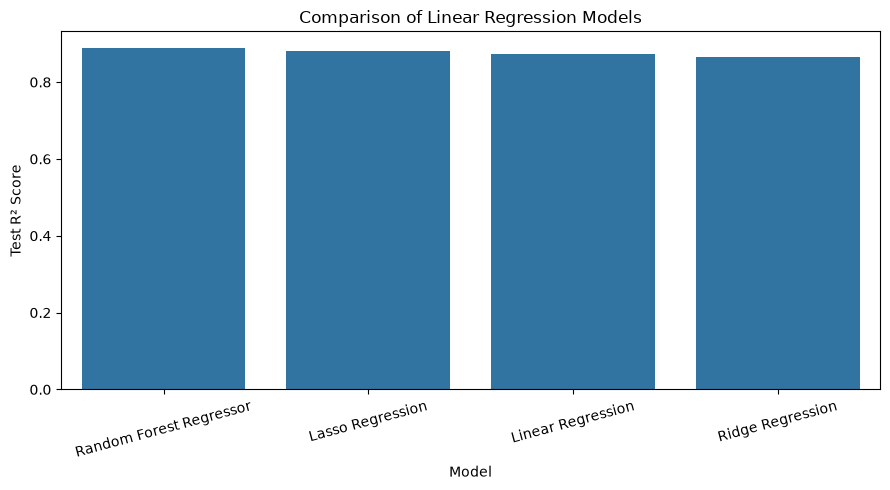

In [13]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=comparison_df.index,
    y=comparison_df["R2 Score"]
)

plt.title("Comparison of Linear Regression Models")
plt.xlabel("Model")
plt.ylabel("Test R² Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

#### **Stage 2 — Feature Selection with Hyperparameter Tuning + Cross-Validation**

##### **Section 1 – Data separation + Feature Selection**

In [14]:
# Read low-correlation feature names
feature_file = r"C:\Users\idris\OneDrive\Desktop\Master_AI\Applied_ML\Assignment 1\house-prices-advanced-regression-techniques\selected_features.txt"

with open(feature_file, "r") as file:
    selected_features = [line.strip() for line in file if line.strip()]

# Separate independent features (X) and dependent target (y)

# Training dataset
X_train = train_df.drop(columns=["SalePrice"] + selected_features, errors="ignore")
y_train = train_df["SalePrice"]

# Testing dataset
X_test = test_df.drop(columns=["SalePrice"] + selected_features, errors="ignore")
y_test = test_df["SalePrice"]

# Display shapes
print("X_train Shape:", X_train.shape)
print("y_train Shape:", y_train.shape)

print("X_test Shape:", X_test.shape)
print("y_test Shape:", y_test.shape)

X_train Shape: (1103, 206)
y_train Shape: (1103,)
X_test Shape: (275, 206)
y_test Shape: (275,)


##### **Section 2 – Feature Scaling**

In [15]:
# Load numerical feature names
numerical_features_path = r"C:\Users\idris\OneDrive\Desktop\Master_AI\Applied_ML\Assignment 1\house-prices-advanced-regression-techniques\numerical_features.txt"

with open(numerical_features_path, "r") as file:
    numerical_cols = file.read().splitlines()

# Keep only numerical columns available in both datasets
numerical_cols = [
    col for col in numerical_cols
    if col in X_train.columns and col in X_test.columns
]

# Initialize StandardScaler
scaler = StandardScaler()

# Fit on training data and transform
X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])

# Transform testing data using the same scaler
X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])

print("Numerical features scaled successfully.")

print("Number of scaled features:", len(numerical_cols))
print("X_train Shape:", X_train.shape)
display(X_train.head())
print()
print("X_test Shape:", X_test.shape)
display(X_test.head())

Numerical features scaled successfully.
Number of scaled features: 16
X_train Shape: (1103, 206)


,LotFrontage,LotArea,Street,LotShape,LandSlope,OverallQual,YearBuilt,YearRemodAdd,MasVnrArea,ExterQual,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,-0.035793,-0.224844,1,4,1,-0.908830,-0.528479,-1.382740,-0.616811,3,...,0,0,0,1,0,0,0,0,1,0
1,-0.524836,-0.275947,1,3,1,-0.156248,0.682208,0.421320,-0.616811,4,...,0,0,0,1,0,0,0,0,1,0
2,-0.480377,-0.333767,1,4,1,-0.908830,-1.201082,-1.724049,0.816650,3,...,0,0,0,1,0,0,0,0,1,0
3,-0.924962,-0.533459,1,4,1,-0.908830,-1.638274,-1.724049,-0.616811,3,...,0,0,0,1,0,0,0,0,1,0
4,-0.035793,-0.097767,1,4,1,-0.908830,-0.024026,-0.651364,-0.616811,3,...,0,0,0,1,1,0,0,0,0,0



X_test Shape: (275, 206)


,LotFrontage,LotArea,Street,LotShape,LandSlope,OverallQual,YearBuilt,YearRemodAdd,MasVnrArea,ExterQual,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,-0.035793,-0.223573,1,4,1,-0.156248,-0.326697,0.860146,-0.616811,3,...,0,0,0,1,0,0,0,0,1,0
1,1.209045,0.125162,1,3,1,1.348917,0.715838,0.470079,1.442367,4,...,0,0,0,1,0,0,0,0,1,0
2,-0.658211,-0.174013,1,4,1,-0.908830,-1.537384,-1.724049,-0.616811,3,...,0,0,0,1,0,0,0,0,1,0
3,-0.924962,-0.533459,1,4,1,-0.156248,-0.864780,-1.724049,-0.616811,3,...,0,0,0,1,0,0,0,0,1,0
4,0.808919,0.183436,1,3,1,2.101499,1.153030,1.103938,-0.218627,4,...,0,0,0,1,0,0,0,0,1,0


##### **Section 3 – Create an evaluation function**

In [16]:
def evaluate_model(model, X_test, y_test):

    # Generate predictions
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    }

##### **Section 4 – Linear Regression — Reference Model**

In [17]:
# Create model
lr_model = LinearRegression()

# Train model
lr_model.fit(X_train, y_train)

print("Linear Regression trained successfully!")

# Evaluate model
lr_results = evaluate_model(lr_model, X_test, y_test)

print("\nLinear Regression Performance")
for metric, value in lr_results.items():
    print(f"{metric}: {value:.4f}")

Linear Regression trained successfully!

Linear Regression Performance
MAE: 21109.5664
MSE: 1022789203.5468
RMSE: 31981.0757
R2 Score: 0.8680


##### **Section 5 – Ridge Regression Hyperparameter Tuning**

In [18]:
# Create pipeline
ridge_pipeline = Pipeline([
    ("model", Ridge())
])

# Hyperparameters to test
ridge_param_grid = {
    "model__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

# Grid Search with 5-fold cross-validation
grid_search_ridge = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

# Train and find the best parameters
grid_search_ridge.fit(X_train, y_train)

print("Best Ridge Parameters:", grid_search_ridge.best_params_)
print("Best Ridge CV R²:", grid_search_ridge.best_score_)

Best Ridge Parameters: {'model__alpha': 10}
Best Ridge CV R²: 0.8008376276171655


In [19]:
# Get best Ridge model
best_ridge = grid_search_ridge.best_estimator_

# Evaluate model
ridge_results = evaluate_model(best_ridge, X_test, y_test)

print("\nRidge Regression Performance")
for metric, value in ridge_results.items():
    print(f"{metric}: {value:.4f}")


Ridge Regression Performance
MAE: 19966.6764
MSE: 1065661756.8888
RMSE: 32644.4751
R2 Score: 0.8625


##### **Section 6 – Lasso Regression Hyperparameter Tuning**

In [20]:
# Create pipeline
lasso_pipeline = Pipeline([
    ("model", Lasso(max_iter=20000))
])

# Hyperparameters to test
lasso_param_grid = {
    "model__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

# Grid Search with 5-fold cross-validation
grid_search_lasso = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

# Train and find the best parameters
grid_search_lasso.fit(X_train, y_train)

print("Best Lasso Parameters:", grid_search_lasso.best_params_)
print("Best Lasso CV R²:", grid_search_lasso.best_score_)

Best Lasso Parameters: {'model__alpha': 100}
Best Lasso CV R²: 0.7870762764810382


In [21]:
# Get best Lasso model
best_lasso = grid_search_lasso.best_estimator_

# Evaluate model
lasso_results = evaluate_model(best_lasso, X_test, y_test)

print("\nLasso Regression Performance")
for metric, value in lasso_results.items():
    print(f"{metric}: {value:.4f}")


Lasso Regression Performance
MAE: 19316.4567
MSE: 971025048.5879
RMSE: 31161.2748
R2 Score: 0.8747


##### **Section 7 – Random Forest Regressor Hyperparameter Tuning**

In [22]:
# Initialize Random Forest
rf = RandomForestRegressor(random_state=42, n_jobs=1)

# Define hyperparameter search space
param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 10, 20, 30, 40],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [0.5, 0.7, 1.0]
}

# Hyperparameter tuning
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=30,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    random_state=42,
    verbose=1
)

# Train using training data only
random_search.fit(X_train, y_train)

# Best parameters
print("Best Parameters:")
print(random_search.best_params_)

# Best model
best_rf = random_search.best_estimator_

# Predict testing data
y_pred = best_rf.predict(X_test)

# Evaluate model
rf_results = {
    "MAE": mean_absolute_error(y_test, y_pred),
    "MSE": mean_squared_error(y_test, y_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
    "R2 Score": r2_score(y_test, y_pred)
}

print("\nRandom Forest - Tuned Model Performance")

for metric, value in rf_results.items():
    print(f"{metric}: {value:.4f}")

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters:
{'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': 20}

Random Forest - Tuned Model Performance
MAE: 18157.4107
MSE: 908317867.4039
RMSE: 30138.3123
R2 Score: 0.8828


##### **Section 8 – Models Comparison**

In [23]:
# Combine results
comparison_df = pd.DataFrame({
    "Linear Regression": lr_results,
    "Ridge Regression": ridge_results,
    "Lasso Regression": lasso_results,
    "Random Forest Regressor": rf_results
}).T

# Sort by R² score
comparison_df = comparison_df.sort_values(
    by="R2 Score",
    ascending=False
)

display(comparison_df.round(4))

,MAE,MSE,RMSE,R2 Score
Random Forest Regressor,18157.4107,9.083179e+08,30138.3123,0.8828
Lasso Regression,19316.4567,9.710250e+08,31161.2748,0.8747
Linear Regression,21109.5664,1.022789e+09,31981.0757,0.8680
Ridge Regression,19966.6764,1.065662e+09,32644.4751,0.8625


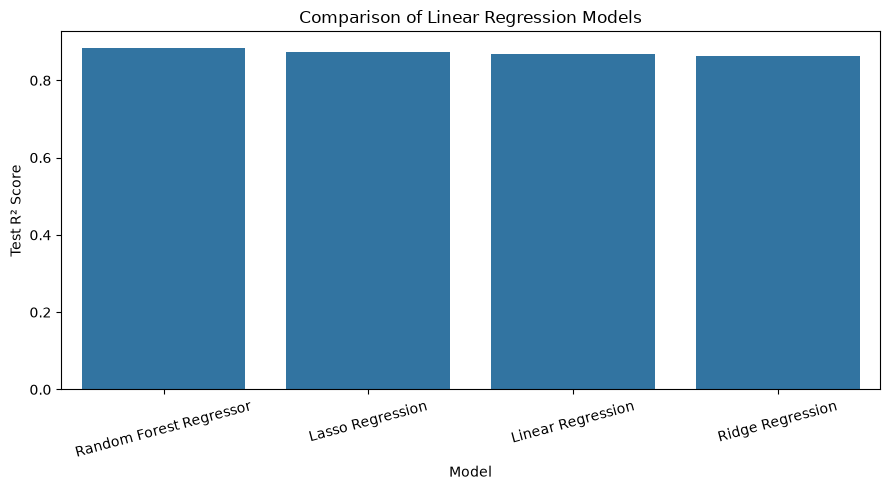

In [24]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=comparison_df.index,
    y=comparison_df["R2 Score"]
)

plt.title("Comparison of Linear Regression Models")
plt.xlabel("Model")
plt.ylabel("Test R² Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()